# 01 — Phân tích dữ liệu phục vụ tiền xử lý (EDA)

**Dữ liệu:** `dataset/quickdraw_100c_30k.parquet` — 100 lớp × 30.000 hình vẽ, lấy từ
`train_simplified` của cuộc thi Kaggle *Quick, Draw! Doodle Recognition*.

**Mục tiêu:** đo các đặc tính của dữ liệu mà mỗi quyết định tiền xử lý phụ thuộc vào
(làm sạch, chia tập, chuẩn hoá toạ độ, định nghĩa prefix, độ dài chuỗi, raster).
Mọi con số trong notebook được tính trên **toàn bộ 3.000.000 mẫu**, trừ phần prefix
(mục 9) dùng mẫu phân tầng 1.000 hình/lớp và được ghi rõ.

**Thứ tự chạy:** chạy từ trên xuống. Lần đầu sẽ tự tính bảng thống kê từng hình vẽ
(`dataset/derived/drawing_stats.parquet`, vài phút); các lần sau đọc lại từ cache.
Hình lưu ở `reports/eda/figures/`, bảng ở `reports/eda/tables/`.

In [1]:
import hashlib
import json
import math
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

from quickdraw.io import (CLASSES_PATH, PARQUET_PATH, SELECTION_DIR, load_classes,
                          load_drawings)
from quickdraw.prefix import PREFIX_FNS, bbox
from quickdraw.stats import load_stats
from quickdraw.viz import mean_corr, plot_strokes, rasterize, renormalize

FIG = ROOT / "reports" / "eda" / "figures"
TAB = ROOT / "reports" / "eda" / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)
SEED = 42
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "font.size": 9})


def savefig(name):
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")


def pct(x):
    return f"{100 * x:.2f}%"


FINDINGS = []  # (mục, chỉ số, giá trị) — tổng hợp ở mục 12


def finding(section, name, value):
    FINDINGS.append((section, name, value))
    print(f"[{section}] {name}: {value}")

## 1. Tổng quan và tính toàn vẹn của file

In [2]:
pf = pq.ParquetFile(PARQUET_PATH)
print(pf.schema_arrow)
print(f"rows={pf.metadata.num_rows:,}  row_groups={pf.num_row_groups}  "
      f"size={PARQUET_PATH.stat().st_size / 2**20:.0f} MiB")

df = load_stats()
classes = load_classes()
print(df.shape)
df.head()

countrycode: string
drawing: string
key_id: int64
recognized: bool
word: string
label: int64
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 768
rows=3,000,000  row_groups=3  size=643 MiB


(3000000, 19)


,row,key_id,label,word,recognized,countrycode,n_strokes,n_points,min_stroke_points,max_stroke_points,n_single_point_strokes,xmin,ymin,xmax,ymax,n_out_of_range,ink_length,first_stroke_ink_share,drawing_hash
0,0,5345024160038912,0,The Mona Lisa,False,US,31,134,2,9,0,1,0,255,139,0,2099.864112,0.010497,-2731257918829534895
1,1,5945154504491008,0,The Mona Lisa,True,RO,5,63,2,19,0,0,0,144,254,0,1754.104037,0.418111,5745990489001099223
2,2,5456576087326720,0,The Mona Lisa,True,CZ,6,63,2,28,0,0,0,255,235,0,1570.639576,0.135402,3654603579408607373
3,3,6590476645826560,0,The Mona Lisa,True,AE,8,71,4,17,0,1,0,108,245,0,1565.566145,0.214306,-4190331105688387739
4,4,6071622618316800,0,The Mona Lisa,True,US,3,41,9,16,0,1,0,255,241,0,1553.320599,0.606610,-1849748981188416699


In [3]:
# Tính toàn vẹn: label <-> word 1-1, thứ tự label khớp file classes, khớp danh sách đã đóng băng.
label_word = df.drop_duplicates(["label", "word"]).sort_values("label")
assert df.groupby("label")["word"].nunique().max() == 1
assert df.groupby("word")["label"].nunique().max() == 1
assert label_word["word"].tolist() == classes, "label order != quickdraw_100c_30k_classes.txt"

frozen_txt = (SELECTION_DIR / "classes.txt").read_bytes()
freeze = json.loads((SELECTION_DIR / "freeze_info.json").read_text(encoding="utf-8"))
frozen = pd.read_csv(SELECTION_DIR / "classes_frozen.csv")
print("sha256(classes.txt) khớp freeze_info:", hashlib.sha256(frozen_txt).hexdigest() == freeze["sha256_classes_txt"])
print("classes.txt == quickdraw_100c_30k_classes.txt:", frozen_txt.decode("utf-8").splitlines() == classes)
print("classes_frozen.csv == danh sách lớp:", sorted(frozen["class"]) == sorted(classes))

counts = df["word"].value_counts()
finding("1", "số mẫu", f"{len(df):,}")
finding("1", "số lớp", df["word"].nunique())
finding("1", "mẫu/lớp (min–max)", f"{counts.min():,}–{counts.max():,}")
finding("1", "key_id trùng", int(df["key_id"].duplicated().sum()))
print("\nGiá trị thiếu theo cột:")
print(df[["key_id", "label", "word", "recognized", "countrycode"]].isna().sum())

sha256(classes.txt) khớp freeze_info: True
classes.txt == quickdraw_100c_30k_classes.txt: True
classes_frozen.csv == danh sách lớp: True
[1] số mẫu: 3,000,000
[1] số lớp: 100
[1] mẫu/lớp (min–max): 30,000–30,000


[1] key_id trùng: 0

Giá trị thiếu theo cột:
key_id           0
label            0
word             0
recognized       0
countrycode    114
dtype: int64


## 2. Trùng lặp

Hai hình được coi là trùng khi chuỗi `drawing` giống hệt nhau (so bằng hash
blake2b 64-bit, sau đó **so lại chuỗi gốc** để loại trừ va chạm hash).

In [4]:
dup = df[df.duplicated("drawing_hash", keep=False)]
groups = (dup.groupby("drawing_hash")
             .agg(n=("row", "size"), n_classes=("word", "nunique"),
                  words=("word", lambda s: " | ".join(sorted(set(s)))),
                  n_points=("n_points", "first"), n_strokes=("n_strokes", "first"),
                  rows=("row", list))
             .sort_values(["n_classes", "n"], ascending=False))

# Xác minh không có va chạm hash: mọi hàng trong một nhóm phải có chuỗi giống hệt.
dup_drawings = dict(zip(dup["row"], load_drawings(dup["row"])))
collisions = sum(len({json.dumps(dup_drawings[r]) for r in rows}) > 1 for rows in groups["rows"])
print("va chạm hash:", collisions)

cross = groups[groups["n_classes"] > 1]
within = groups[groups["n_classes"] == 1]
finding("2", "nhóm hình trùng", len(groups))
finding("2", "hàng thừa (tổng - số nhóm)", int(groups["n"].sum() - len(groups)))
finding("2", "nhóm trùng cùng lớp", len(within))
finding("2", "nhóm trùng khác lớp (mâu thuẫn nhãn)", len(cross))
finding("2", "số hàng thuộc nhóm khác lớp", int(cross["n"].sum()))
print("\nKích thước nhóm:", groups["n"].value_counts().to_dict())
print("Số điểm của hình trùng (median):", groups["n_points"].median(),
      "| toàn bộ dữ liệu:", df["n_points"].median())
groups.drop(columns="rows").to_csv(TAB / "duplicate_groups.csv")
cross.drop(columns="rows").head(15)

va chạm hash: 0
[2] nhóm hình trùng: 39
[2] hàng thừa (tổng - số nhóm): 60
[2] nhóm trùng cùng lớp: 0
[2] nhóm trùng khác lớp (mâu thuẫn nhãn): 39
[2] số hàng thuộc nhóm khác lớp: 99

Kích thước nhóm: {2: 26, 3: 8, 4: 3, 6: 1, 5: 1}
Số điểm của hình trùng (median): 2.0 | toàn bộ dữ liệu: 41.0


,n,n_classes,words,n_points,n_strokes
drawing_hash,,,,,
-2265162195629275792,6,6,ant | camouflage | finger | mouth | square | t...,2,1
-8477445599656856019,5,5,helmet | lobster | megaphone | owl | rake,2,1
-1981730231917324679,4,4,floor lamp | hand | popsicle | purse,2,1
2697195065256364447,4,4,drill | face | mouth | square,2,1
8761745608508053356,4,4,helicopter | jacket | lobster | snowman,2,1
-8086389818638058108,3,3,apple | sock | tractor,2,1
-7851315838643554776,3,3,ant | castle | scissors,2,1
-1372653167841359097,3,3,bird | square | waterslide,2,1
-1107345549458439025,3,3,The Mona Lisa | church | square,2,1


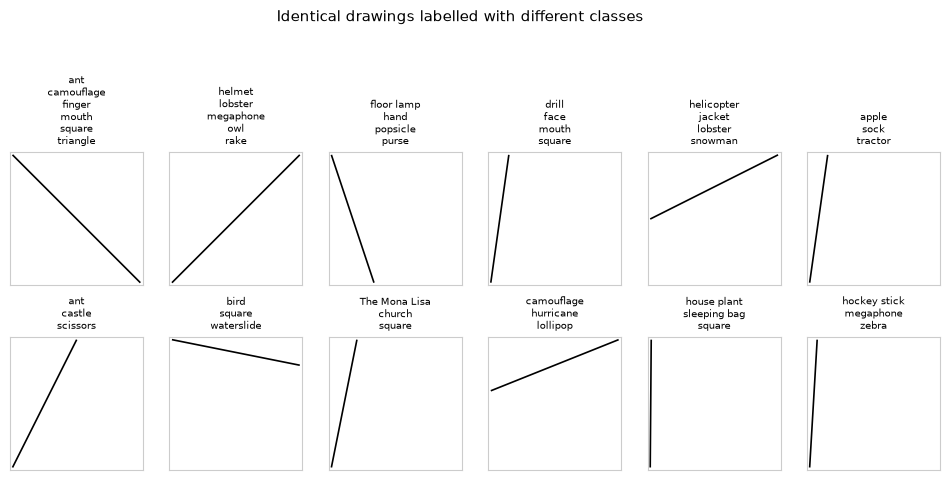

In [5]:
show = cross.head(12)
fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
for ax, (_, g) in zip(axes.flat, show.iterrows()):
    plot_strokes(ax, dup_drawings[g["rows"][0]], title=g["words"].replace(" | ", "\n"))
for ax in axes.flat[len(show):]:
    ax.axis("off")
fig.suptitle("Identical drawings labelled with different classes", y=1.18)
savefig("02_cross_class_duplicates")
plt.show()

**Nhận xét.** Không có va chạm hash và không có hình trùng trong cùng một lớp. Toàn bộ
39 nhóm trùng đều **khác lớp** (99 hàng) và đều là **một đoạn thẳng 2 điểm**: một nét
gạch không mang thông tin về lớp, nên nhãn của chúng thực chất là ngẫu nhiên.
Dữ liệu không có trùng lặp "thật" giữa các hình có nội dung.

→ **Quyết định:** loại 99 hàng này. Chúng cũng nằm trong nhóm hình quá ít điểm ở mục 3.
Hình gần trùng (lệch vài pixel) không được kiểm tra ở đây và vẫn là một giới hạn.

## 3. Hình suy biến

Kiểm tra hình có quá ít điểm, bề rộng hoặc chiều cao bằng 0, nét chỉ có 1 điểm,
và toạ độ nằm ngoài khoảng [0, 255].

In [6]:
df["width"] = df["xmax"] - df["xmin"]
df["height"] = df["ymax"] - df["ymin"]
df["long_side"] = df[["width", "height"]].max(axis=1)

for k in (1, 2, 3, 5):
    finding("3", f"hình có ≤ {k} điểm", int((df["n_points"] <= k).sum()))
finding("3", "hình có bề rộng = 0", int((df["width"] == 0).sum()))
finding("3", "hình có chiều cao = 0", int((df["height"] == 0).sum()))
finding("3", "hình có ít nhất 1 nét 1 điểm", int((df["n_single_point_strokes"] > 0).sum()))
finding("3", "hình có toạ độ ngoài [0,255]", int((df["n_out_of_range"] > 0).sum()))
finding("3", "hình có ink_length = 0", int((df["ink_length"] == 0).sum()))

tiny = df[df["n_points"] <= 3]
print("\nLớp có nhiều hình ≤ 3 điểm nhất:")
print(tiny["word"].value_counts().head(10).to_dict())
print("Tỉ lệ recognized trong nhóm ≤ 3 điểm:", pct(tiny["recognized"].mean()))

[3] hình có ≤ 1 điểm: 0
[3] hình có ≤ 2 điểm: 298
[3] hình có ≤ 3 điểm: 851
[3] hình có ≤ 5 điểm: 2759
[3] hình có bề rộng = 0: 3
[3] hình có chiều cao = 0: 1
[3] hình có ít nhất 1 nét 1 điểm: 0
[3] hình có toạ độ ngoài [0,255]: 0
[3] hình có ink_length = 0: 51

Lớp có nhiều hình ≤ 3 điểm nhất:
{'mouth': 27, 'diamond': 24, 'square': 22, 'wine bottle': 21, 'sock': 19, 'finger': 18, 'hockey stick': 18, 'tornado': 18, 'fence': 17, 'rake': 17}
Tỉ lệ recognized trong nhóm ≤ 3 điểm: 71.68%


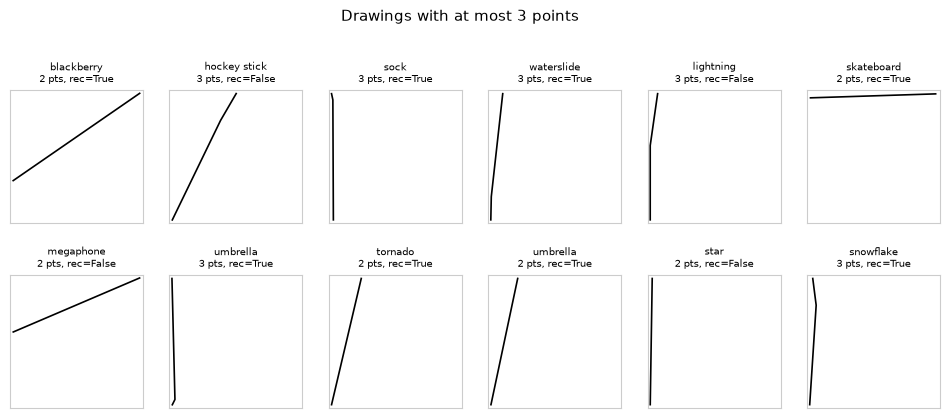

In [7]:
sample_tiny = tiny.sample(min(12, len(tiny)), random_state=SEED)
fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
for ax, (_, r), d in zip(axes.flat, sample_tiny.iterrows(), load_drawings(sample_tiny["row"])):
    plot_strokes(ax, d, title=f"{r['word']}\n{r['n_points']} pts, rec={r['recognized']}")
fig.suptitle("Drawings with at most 3 points", y=1.04)
savefig("03_tiny_drawings")
plt.show()

Có hình độ dài mực bằng 0 nhưng khung bao khác 0: đó là hình chỉ gồm **chấm**
(mỗi nét là 2 điểm trùng nhau ở cùng vị trí).

Số nét của hình độ dài mực = 0: {2: 25, 3: 13, 4: 3, 5: 2, 6: 1, 7: 1, 8: 2, 12: 2, 22: 1, 138: 1}
Theo lớp: {'blackberry': 4, 'helicopter': 3, 'bracelet': 2, 'camouflage': 2, 'chandelier': 2, 'rake': 2, 'teddy-bear': 2, 'ant': 1}
Tỉ lệ recognized: 3.92%


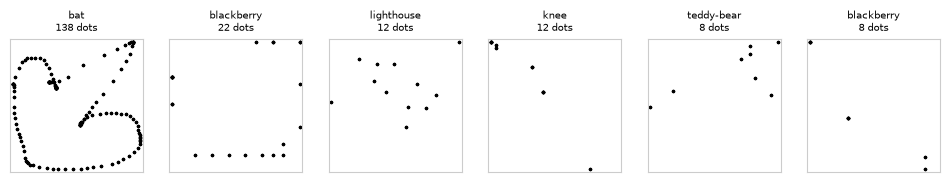

In [8]:
zero_ink = df[df["ink_length"] == 0]
print("Số nét của hình độ dài mực = 0:", zero_ink["n_strokes"].value_counts().sort_index().to_dict())
print("Theo lớp:", zero_ink["word"].value_counts().head(8).to_dict())
print("Tỉ lệ recognized:", pct(zero_ink["recognized"].mean()))
show = zero_ink.sort_values("n_strokes", ascending=False).head(6)
fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
for ax, (_, r), d in zip(axes, show.iterrows(), load_drawings(show["row"])):
    for xs, ys in d:
        ax.plot(xs, ys, "k.", ms=3)
    plot_strokes(ax, [], title=f"{r['word']}\n{r['n_strokes']} dots")
savefig("03_zero_ink_dots")
plt.show()

**Nhận xét.** 851 hình (0,03%) có ≤ 3 điểm, trong đó 298 hình chỉ là một đoạn thẳng
2 điểm. Dù vậy 71,7% trong số đó vẫn được đánh `recognized=True`, vì các lớp như
*mouth, square, finger, hockey stick* có thể được đoán chỉ từ một nét. Không hình nào
có toạ độ ngoài [0, 255] hoặc có nét chỉ 1 điểm. 51 hình hoàn toàn là chấm, và chỉ 3,9% trong số đó được recognized: có thể là lỗi thiết bị nhập hoặc vẽ bằng cách chấm.

→ **Quyết định:** loại các hình trùng khác lớp (mục 2). Với hình ≤ 3 điểm, *gắn cờ*
thay vì loại, vì chúng hợp lệ ở một số lớp và số lượng không đáng kể. Hàm vẽ raster
phải vẽ được **đoạn có độ dài 0 thành một chấm**, nếu không 51 hình chấm sẽ thành ảnh trắng.

## 4. Chuẩn hoá toạ độ

Theo mô tả của Kaggle, dữ liệu *simplified* đã được căn về góc trên-trái (min = 0)
và scale sao cho giá trị lớn nhất là 255. Mục này kiểm tra điều đó có đúng với
**mọi** hình hay không, và nếu không thì lệch bao nhiêu.

In [9]:
df["min_at_zero"] = (df["xmin"] == 0) & (df["ymin"] == 0)
df["max_255"] = df[["xmax", "ymax"]].max(axis=1) == 255
df["conform"] = df["min_at_zero"] & df["max_255"]

finding("4", "hình đúng chuẩn (min=0 và max=255)", pct(df["conform"].mean()))
finding("4", "hình có min x,y = 0", pct(df["min_at_zero"].mean()))
finding("4", "hình có max(x,y) = 255", pct(df["max_255"].mean()))

viol = df[~df["conform"]]
print("\nPhân rã các hình không đúng chuẩn:")
print(pd.crosstab(viol["min_at_zero"], viol["max_255"], margins=True))
print("\nxmin, ymin, long_side của hình không đúng chuẩn:")
print(viol[["xmin", "ymin", "xmax", "ymax", "long_side"]].describe(percentiles=[.05, .25, .5, .75, .95]).round(1))

[4] hình đúng chuẩn (min=0 và max=255): 71.80%
[4] hình có min x,y = 0: 80.58%
[4] hình có max(x,y) = 255: 88.61%



Phân rã các hình không đúng chuẩn:
max_255       False    True     All
min_at_zero                        
False         78563  504172  582735
True         263133       0  263133
All          341696  504172  845868

xmin, ymin, long_side của hình không đúng chuẩn:


           xmin      ymin      xmax      ymax  long_side
count  845868.0  845868.0  845868.0  845868.0   845868.0
mean        0.5       0.4     223.1     211.2      254.0
std         0.9       0.7      47.8      52.2        1.2
min         0.0       0.0       1.0       2.0      104.0
5%          0.0       0.0     116.0     107.0      253.0
25%         0.0       0.0     200.0     174.0      254.0
50%         0.0       0.0     254.0     237.0      254.0
75%         1.0       1.0     255.0     255.0      255.0
95%         1.0       1.0     255.0     255.0      255.0
max       151.0      71.0     255.0     255.0      255.0


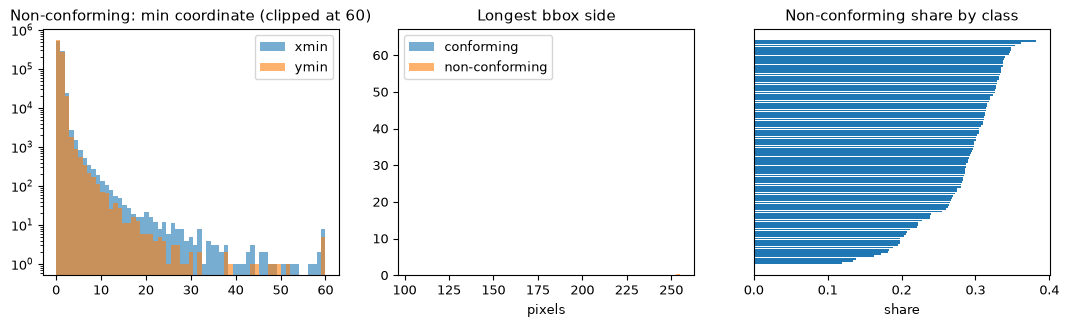

5 lớp có tỉ lệ không đúng chuẩn cao nhất: {'rabbit': 0.348, 'sleeping bag': 0.349, 'tractor': 0.353, 'monkey': 0.361, 'teddy-bear': 0.382}
5 lớp thấp nhất: {'sun': 0.12, 'snowflake': 0.134, 'mountain': 0.139, 'nose': 0.162, 'diamond': 0.173}
Tỉ lệ recognized: đúng chuẩn 91.75% | không đúng chuẩn 91.77%


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
axes[0].hist(np.minimum(viol["xmin"], 60), bins=61, alpha=.6, label="xmin")
axes[0].hist(np.minimum(viol["ymin"], 60), bins=61, alpha=.6, label="ymin")
axes[0].set(title="Non-conforming: min coordinate (clipped at 60)", yscale="log")
axes[0].legend()
axes[1].hist(df.loc[df["conform"], "long_side"], bins=64, alpha=.6, density=True, label="conforming")
axes[1].hist(viol["long_side"], bins=64, alpha=.6, density=True, label="non-conforming")
axes[1].set(title="Longest bbox side", xlabel="pixels")
axes[1].legend()
rate = (~df["conform"]).groupby(df["word"]).mean().sort_values()
axes[2].barh(range(len(rate)), rate.values)
axes[2].set(title="Non-conforming share by class", yticks=[], xlabel="share")
savefig("04_normalization")
plt.show()
print("5 lớp có tỉ lệ không đúng chuẩn cao nhất:", rate.tail(5).round(3).to_dict())
print("5 lớp thấp nhất:", rate.head(5).round(3).to_dict())
print("Tỉ lệ recognized: đúng chuẩn", pct(df.loc[df["conform"], "recognized"].mean()),
      "| không đúng chuẩn", pct(viol["recognized"].mean()))

Phần lớn hình "không đúng chuẩn" chỉ lệch 1–2 pixel. Ta tách mức độ lệch:
`offset = max(xmin, ymin)` và `max_coord = max(xmax, ymax)`.

In [11]:
df["offset"] = df[["xmin", "ymin"]].max(axis=1)
df["max_coord"] = df[["xmax", "ymax"]].max(axis=1)
for k in (0, 1, 2):
    print(f"offset ≤ {k}: {pct((df['offset'] <= k).mean())}")
for k in (255, 254, 253):
    print(f"max_coord ≥ {k}: {pct((df['max_coord'] >= k).mean())}")
df["severe_nonconform"] = (df["offset"] > 2) | (df["max_coord"] < 253)
finding("4", "lệch ≤ 2px (offset ≤ 2 và max ≥ 253)", pct(1 - df["severe_nonconform"].mean()))
finding("4", "lệch thật sự (offset > 2 hoặc max < 253)", f"{int(df['severe_nonconform'].sum()):,} "
        f"({pct(df['severe_nonconform'].mean())})")
sev = df[df["severe_nonconform"]]
print("Tỉ lệ recognized trong nhóm lệch thật sự:", pct(sev["recognized"].mean()))
print("Lớp có nhiều hình lệch thật sự nhất:", sev["word"].value_counts().head(8).to_dict())

offset ≤ 0: 80.58%
offset ≤ 1: 98.16%
offset ≤ 2: 99.62%
max_coord ≥ 255: 88.61%
max_coord ≥ 254: 98.57%
max_coord ≥ 253: 99.51%
[4] lệch ≤ 2px (offset ≤ 2 và max ≥ 253): 99.15%
[4] lệch thật sự (offset > 2 hoặc max < 253): 25,605 (0.85%)
Tỉ lệ recognized trong nhóm lệch thật sự: 90.26%
Lớp có nhiều hình lệch thật sự nhất: {'lollipop': 990, 'snowflake': 970, 'rake': 940, 'mailbox': 939, 'lighthouse': 822, 'stop sign': 725, 'helicopter': 682, 'church': 615}


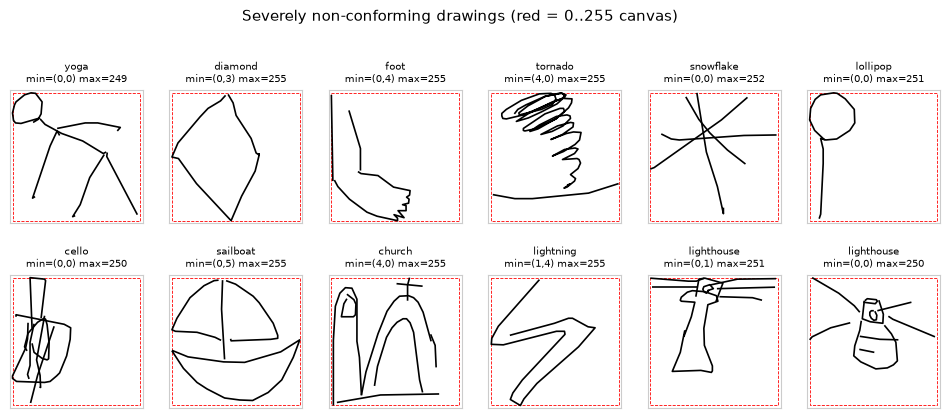

In [12]:
show = sev.sample(12, random_state=SEED)
fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
for ax, (_, r), d in zip(axes.flat, show.iterrows(), load_drawings(show["row"])):
    plot_strokes(ax, d, title=f"{r['word']}\nmin=({r['xmin']},{r['ymin']}) max={r['max_coord']}")
    ax.add_patch(plt.Rectangle((0, 0), 255, 255, fill=False, ec="red", lw=.6, ls="--"))
fig.suptitle("Severely non-conforming drawings (red = 0..255 canvas)", y=1.04)
savefig("04_nonconforming_examples")
plt.show()

**Nhận xét.** Chỉ 71,8% hình thỏa đúng quy ước "min = 0, max = 255", nhưng gần như
toàn bộ phần còn lại chỉ lệch 1–2 pixel (sai số làm tròn khi simplify). Số hình lệch
thật sự nhỏ (xem `finding` ở trên). Tỉ lệ lệch không liên quan tới `recognized`.

→ **Quyết định:** tự chuẩn hoá lại **mọi** hình (dời về 0, scale cạnh dài về 255,
giữ tỉ lệ khung hình) để toạ độ nhất quán. Với hình đầy đủ, ảnh hưởng nhỏ. Điều quan
trọng hơn là cùng một hàm chuẩn hoá được dùng cho prefix (mục 9).

## 5. Cấu trúc nét

In [13]:
q = [.01, .05, .25, .5, .75, .95, .99, .999]
print("Số nét / hình:")
print(df["n_strokes"].quantile(q).to_dict(), "max", df["n_strokes"].max())
df["pts_per_stroke"] = df["n_points"] / df["n_strokes"]
print("Điểm / nét (trung bình trong hình):", df["pts_per_stroke"].quantile(q).round(1).to_dict())
finding("5", "số nét median / p95 / p99", f"{df['n_strokes'].median():.0f} / "
        f"{df['n_strokes'].quantile(.95):.0f} / {df['n_strokes'].quantile(.99):.0f}")
for k in (1, 2, 3):
    finding("5", f"hình có < {k + 1} nét" if k > 1 else "hình chỉ có 1 nét",
            pct((df["n_strokes"] <= k).mean()))
finding("5", "tỉ lệ mực của nét đầu tiên (median)", f"{df['first_stroke_ink_share'].median():.2f}")

single = (df["n_strokes"] == 1).groupby(df["word"]).mean().sort_values(ascending=False)
single.rename("single_stroke_share").to_csv(TAB / "single_stroke_share_by_class.csv")
print("\nLớp có tỉ lệ hình 1 nét cao nhất:", single.head(10).round(3).to_dict())

Số nét / hình:
{0.01: 1.0, 0.05: 1.0, 0.25: 2.0, 0.5: 4.0, 0.75: 7.0, 0.95: 13.0, 0.99: 19.0, 0.999: 31.0} max 342
Điểm / nét (trung bình trong hình): {0.01: 3.1, 0.05: 4.2, 0.25: 6.7, 0.5: 9.6, 0.75: 14.6, 0.95: 35.0, 0.99: 81.0, 0.999: 189.0}


[5] số nét median / p95 / p99: 4 / 13 / 19
[5] hình chỉ có 1 nét: 15.63%
[5] hình có < 3 nét: 29.20%
[5] hình có < 4 nét: 42.28%
[5] tỉ lệ mực của nét đầu tiên (median): 0.43

Lớp có tỉ lệ hình 1 nét cao nhất: {'star': 0.772, 'square': 0.77, 'boomerang': 0.736, 'triangle': 0.734, 'tornado': 0.68, 'hand': 0.671, 'hockey stick': 0.651, 'hurricane': 0.609, 't-shirt': 0.591, 'foot': 0.57}


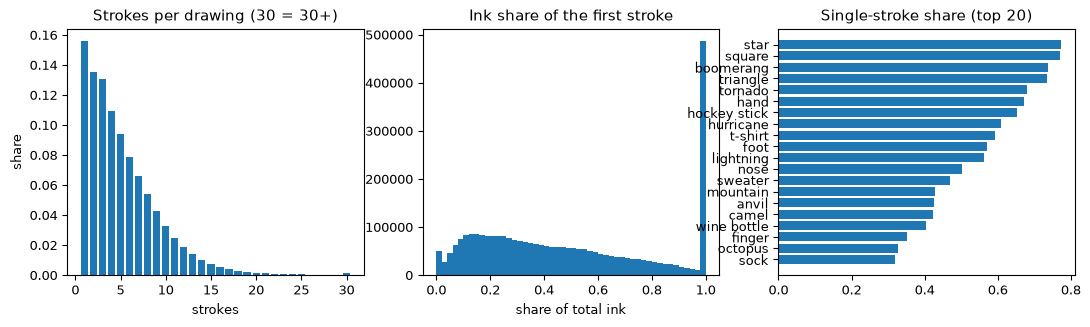

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
vc = df["n_strokes"].clip(upper=30).value_counts().sort_index()
axes[0].bar(vc.index, vc.values / len(df))
axes[0].set(title="Strokes per drawing (30 = 30+)", xlabel="strokes", ylabel="share")
axes[1].hist(df["first_stroke_ink_share"].dropna(), bins=50)
axes[1].set(title="Ink share of the first stroke", xlabel="share of total ink")
axes[2].barh(range(20), single.head(20).values[::-1])
axes[2].set(yticks=range(20), yticklabels=single.head(20).index[::-1], title="Single-stroke share (top 20)")
savefig("05_strokes")
plt.show()

**Nhận xét.** Mỗi hình có median 4 nét, p99 là 19 nét. **15,6% hình chỉ có 1 nét**, và
42,3% có ≤ 3 nét. Tỉ lệ này lệch mạnh giữa các lớp: *star, square, boomerang, triangle*
có trên 73% hình vẽ bằng một nét. Median của nét đầu tiên đã chiếm 43% tổng mực.

→ **Hệ quả cho prefix:** cắt theo số nét rất thô. Với hình 1 nét, "25% đầu" theo số nét
hoặc là rỗng (làm tròn xuống) hoặc là cả hình (làm tròn lên). Cả hai đều không phải
"một phần hình vẽ", và vấn đề tập trung ở một số lớp chứ không phân bố đều (xem mục 9).

## 6. Độ dài chuỗi điểm

Bảng dưới cho biết với mỗi mức cắt (cap) bao nhiêu hình được giữ **nguyên vẹn**,
tính trên toàn bộ và ở lớp tệ nhất.

In [15]:
print("Số điểm / hình:", df["n_points"].quantile(q).to_dict(), "max", df["n_points"].max())
caps = [64, 96, 128, 160, 192, 256, 320]
by_class = df.groupby("word")["n_points"]
coverage = pd.DataFrame({
    "cap": caps,
    "share_all": [(df["n_points"] <= c).mean() for c in caps],
    "share_worst_class": [by_class.apply(lambda s: (s <= c).mean()).min() for c in caps],
    "worst_class": [by_class.apply(lambda s: (s <= c).mean()).idxmin() for c in caps],
})
coverage.to_csv(TAB / "sequence_length_coverage.csv", index=False)
finding("6", "số điểm median / p95 / p99", f"{df['n_points'].median():.0f} / "
        f"{df['n_points'].quantile(.95):.0f} / {df['n_points'].quantile(.99):.0f}")
coverage.style.format({"share_all": "{:.4f}", "share_worst_class": "{:.4f}"})

Số điểm / hình: {0.01: 11.0, 0.05: 16.0, 0.25: 28.0, 0.5: 41.0, 0.75: 58.0, 0.95: 96.0, 0.99: 151.0, 0.999: 303.0} max 1758


[6] số điểm median / p95 / p99: 41 / 96 / 151


,cap,share_all,share_worst_class,worst_class
0,64,0.8136,0.1439,blackberry
1,96,0.9511,0.3633,blackberry
2,128,0.9824,0.6056,blackberry
3,160,0.9920,0.7832,blackberry
4,192,0.9957,0.8825,blackberry
5,256,0.9983,0.9619,blackberry
6,320,0.9992,0.9859,blackberry


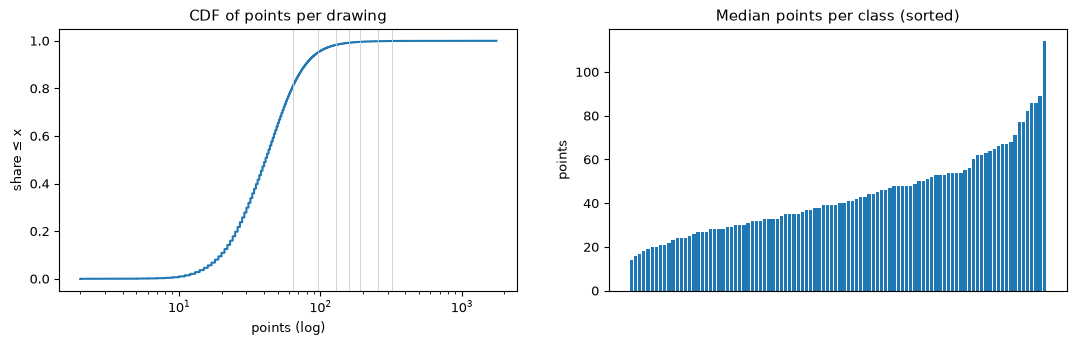

Lớp có median số điểm cao nhất: {'tornado': 82.0, 'camouflage': 86.0, 'grapes': 86.0, 'hurricane': 89.0, 'blackberry': 114.0}
Lớp thấp nhất: {'triangle': 14.0, 'square': 16.0, 'mountain': 17.0, 'knee': 18.0, 'lightning': 19.0}


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
x = np.sort(df["n_points"].values)
axes[0].plot(x, np.arange(1, len(x) + 1) / len(x))
for c in caps:
    axes[0].axvline(c, color="0.8", lw=.6)
axes[0].set(xscale="log", title="CDF of points per drawing", xlabel="points (log)", ylabel="share ≤ x")
med = by_class.median().sort_values()
axes[1].bar(range(len(med)), med.values)
axes[1].set(title="Median points per class (sorted)", xticks=[], ylabel="points")
savefig("06_sequence_length")
plt.show()
print("Lớp có median số điểm cao nhất:", med.tail(5).to_dict())
print("Lớp thấp nhất:", med.head(5).to_dict())

**Nhận xét.** Số điểm có median 41, p95 = 96, p99 = 151 (max 1.758). Tính trên toàn
bộ, cap 160 giữ nguyên 99,2% hình. Nhưng ở lớp tệ nhất (*blackberry*, hình gồm nhiều
chấm) cap 160 chỉ giữ nguyên 78,3% hình, cap 256 giữ 96,2%. Cắt chuỗi sẽ làm mất có
hệ thống phần cuối của các lớp vẽ nhiều chi tiết (*blackberry, hurricane, grapes,
camouflage, tornado*), tức là các lớp không còn được đối xử như nhau.

→ **Quyết định:** chọn cap theo *lớp tệ nhất* chứ không theo trung bình. Đề xuất
**256 điểm**: giữ nguyên 99,8% hình, ≥ 96% ở mọi lớp. Phần vượt cap nên được
**giảm mẫu** (ví dụ RDP với epsilon lớn hơn, hoặc lấy mẫu đều theo độ dài mực) thay vì
cắt cụt phần cuối. Raster không bị ảnh hưởng bởi chuyện này.

## 7. Cờ `recognized` (nhãn có thể nhiễu)

`recognized=False` nghĩa là model của Google không đoán được hình trong lượt chơi —
hình có thể vẽ sai, vẽ dở, người vẽ bỏ cuộc, hoặc chỉ là hình khó.

In [17]:
finding("7", "tỉ lệ recognized=False", pct(1 - df["recognized"].mean()))
rec_by_class = df.groupby("word")["recognized"].mean().sort_values()
finding("7", "recognized rate theo lớp (min–max)",
        f"{rec_by_class.min():.3f} ({rec_by_class.idxmin()}) – {rec_by_class.max():.3f} ({rec_by_class.idxmax()})")
cmp = df.groupby("recognized")[["n_strokes", "n_points", "ink_length", "long_side"]].agg(["mean", "median"]).round(1)
print(cmp)

# So với recognized rate ước lượng lúc chọn lớp (mẫu 3.000 hình/lớp trên dữ liệu gốc).
sel = pd.read_csv(SELECTION_DIR / "class_stats.csv").set_index("class")
both = pd.concat([rec_by_class.rename("ours"), sel["recognized_rate"].rename("selection")], axis=1, join="inner")
print(f"\nTương quan với class_stats.csv: r={both.corr().iloc[0, 1]:.3f}, "
      f"lệch tuyệt đối lớn nhất={((both.ours - both.selection).abs().max()):.3f}")

[7] tỉ lệ recognized=False: 8.24%
[7] recognized rate theo lớp (min–max): 0.815 (bat) – 0.977 (triangle)


           n_strokes        n_points        ink_length         long_side       
                mean median     mean median       mean  median      mean median
recognized                                                                     
False            9.3    8.0     70.3   61.0     1622.7  1240.0     254.7  255.0
True             4.9    4.0     44.9   40.0     1111.0  1004.6     254.7  255.0

Tương quan với class_stats.csv: r=0.994, lệch tuyệt đối lớn nhất=0.014


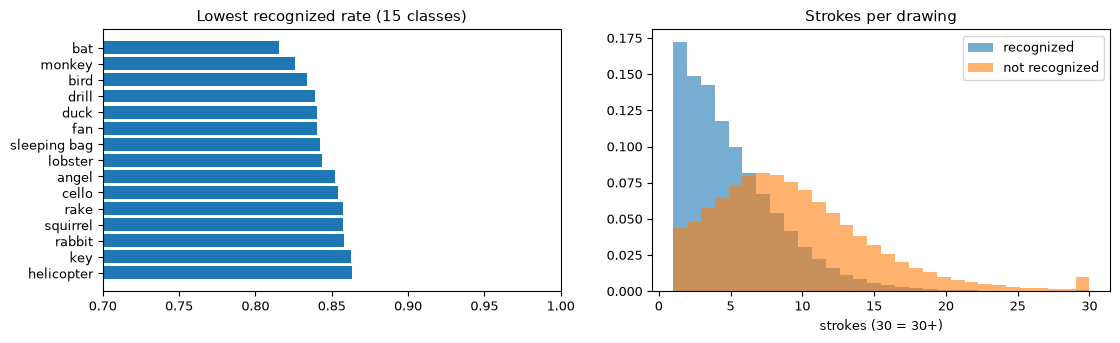

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
axes[0].barh(range(15), rec_by_class.head(15).values[::-1])
axes[0].set(yticks=range(15), yticklabels=rec_by_class.head(15).index[::-1],
            title="Lowest recognized rate (15 classes)", xlim=(0.7, 1))
for flag, lab in ((True, "recognized"), (False, "not recognized")):
    axes[1].hist(df.loc[df["recognized"] == flag, "n_strokes"].clip(upper=30), bins=30,
                 density=True, alpha=.6, label=lab)
axes[1].set(title="Strokes per drawing", xlabel="strokes (30 = 30+)")
axes[1].legend()
savefig("07_recognized")
plt.show()

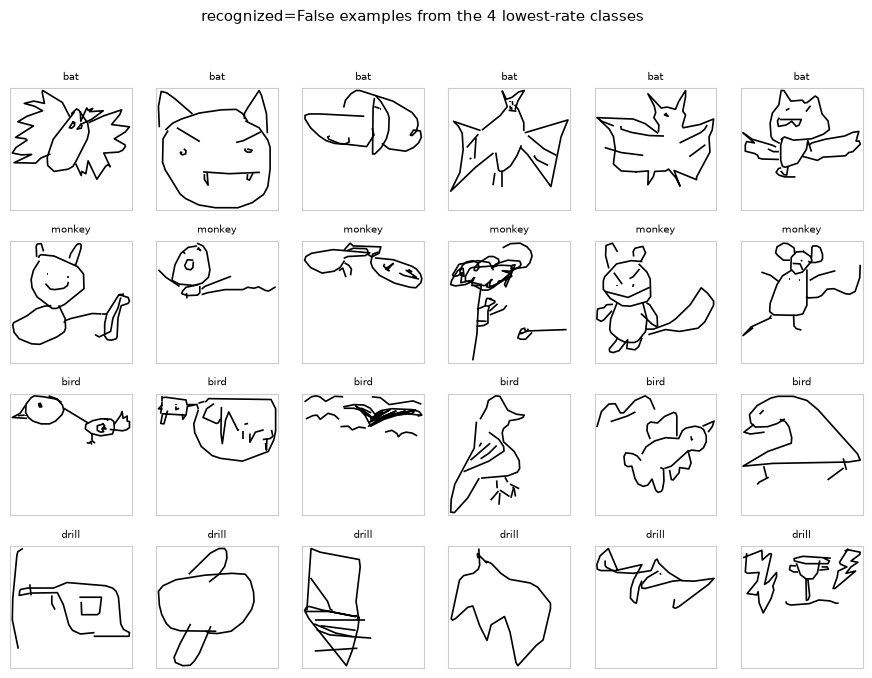

In [19]:
show_classes = rec_by_class.head(4).index.tolist()
rows = [df[(df["word"] == c) & ~df["recognized"]].sample(6, random_state=SEED)["row"] for c in show_classes]
drawings = load_drawings([r for rr in rows for r in rr])
fig, axes = plt.subplots(4, 6, figsize=(11, 7.6))
for ax, d, c in zip(axes.flat, drawings, [c for c in show_classes for _ in range(6)]):
    plot_strokes(ax, d, title=c)
fig.suptitle("recognized=False examples from the 4 lowest-rate classes")
savefig("07_unrecognized_examples")
plt.show()

**Nhận xét.** 8,24% hình có `recognized=False`, dao động từ 81,5% recognized (*bat*) đến
97,7% (*triangle*). Hình không được nhận ra có gần **gấp đôi số nét** (median 8 so với 4)
và nhiều điểm hơn; median số nét cao hơn ở cả 100/100 lớp. Vì vậy đây là nhiễu **có cấu
trúc**, không phải nhiễu nhãn ngẫu nhiên.
Tỉ lệ theo lớp khớp với ước lượng lúc chọn lớp (r = 0,994), nên mẫu dùng để chọn lớp đại diện tốt.

→ **Quyết định:** **giữ** các hình này kèm cột `recognized`. Lọc bỏ hay giữ khi train
là thí nghiệm của nhóm train. Tập val/test phải giữ đủ cả hai để báo cáo riêng
từng nhóm. 

**Cập nhật từ pilot raw (2 lớp, `reports/preprocessing/leak_audit.md`):** dữ liệu simplified
không có thời gian, nên EDA này không kiểm tra được cơ chế dừng. Trên file raw của *triangle* và
*bat*, hình recognized kết thúc sớm hơn hẳn (median 1,9 và 9,1 giây, so với 15,7 và 16,6 giây),
phù hợp với việc lượt chơi dừng khi được nhận ra. Hình không được nhận ra không đồng nhất: khoảng
một nửa kết thúc trong 15–20 giây, nhưng 25–30% kết thúc trước giây 10. Vì vậy **mốc 100% nghĩa là
"lúc lượt vẽ dừng", không phải "vẽ xong"**.

## 8. Quốc gia

Không có user id, nên quốc gia là biến nhóm duy nhất có sẵn — dùng để đo thiên lệch
và làm cơ sở cho một tập test ngoài phân phối (nếu nhóm chọn làm).

In [20]:
cc = df["countrycode"].fillna("<missing>")
vc = cc.value_counts()
finding("8", "số quốc gia", int(df["countrycode"].nunique()))
finding("8", "thiếu countrycode", int(df["countrycode"].isna().sum()))
finding("8", "tỉ lệ US", pct(vc["US"] / len(df)))
finding("8", "tỉ lệ 10 nước lớn nhất", pct(vc.head(10).sum() / len(df)))
finding("8", "số nước có ≥ 1.000 mẫu", int((vc >= 1000).sum()))

per_class_top = df.groupby("word")["countrycode"].agg(lambda s: s.value_counts(normalize=True).iloc[0])
print("Tỉ lệ nước lớn nhất trong từng lớp:", per_class_top.describe().round(3).to_dict())

ctab = pd.crosstab(cc, df["word"])
country = pd.DataFrame({
    "n": vc,
    "share": vc / len(df),
    "min_per_class": ctab.min(axis=1).reindex(vc.index),
    "recognized_rate": df.groupby(cc)["recognized"].mean().reindex(vc.index),
})
country.to_csv(TAB / "countries.csv")
country.head(25).style.format({"share": "{:.4f}", "recognized_rate": "{:.3f}"})

[8] số quốc gia: 207
[8] thiếu countrycode: 114
[8] tỉ lệ US: 44.26%
[8] tỉ lệ 10 nước lớn nhất: 69.93%
[8] số nước có ≥ 1.000 mẫu: 84


Tỉ lệ nước lớn nhất trong từng lớp: {'count': 100.0, 'mean': 0.443, 'std': 0.029, 'min': 0.369, '25%': 0.425, '50%': 0.444, '75%': 0.456, 'max': 0.562}


,n,share,min_per_class,recognized_rate
countrycode,,,,
US,1327680,0.4426,11061,0.916
GB,216372,0.0721,1497,0.913
CA,108837,0.0363,961,0.925
DE,96142,0.0320,460,0.950
AU,70680,0.0236,623,0.920
RU,70522,0.0235,307,0.933
BR,54246,0.0181,311,0.954
FI,52279,0.0174,386,0.923
SE,52067,0.0174,373,0.921


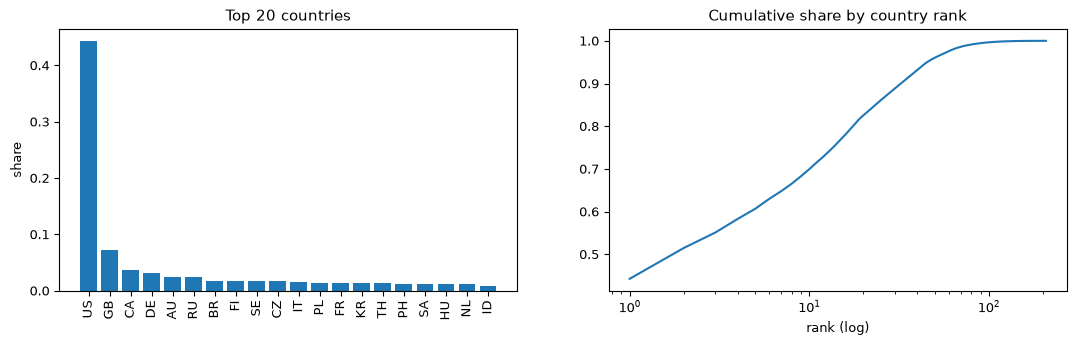

Recognized rate giữa các nước ≥ 10.000 mẫu: 0.795 (SA) – 0.954 (JP)
Số nước có ≥ 30 mẫu ở MỌI lớp: 52
Số nước có ≥ 50 mẫu ở MỌI lớp: 46
Số nước có ≥ 100 mẫu ở MỌI lớp: 30


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
top = country.head(20)
axes[0].bar(top.index, top["share"])
axes[0].set(title="Top 20 countries", ylabel="share")
axes[0].tick_params(axis="x", rotation=90)
axes[1].plot(np.arange(1, len(vc) + 1), vc.cumsum().values / len(df))
axes[1].set(xscale="log", title="Cumulative share by country rank", xlabel="rank (log)")
savefig("08_countries")
plt.show()

big = country[country["n"] >= 10_000]
print("Recognized rate giữa các nước ≥ 10.000 mẫu:",
      f"{big['recognized_rate'].min():.3f} ({big['recognized_rate'].idxmin()}) – "
      f"{big['recognized_rate'].max():.3f} ({big['recognized_rate'].idxmax()})")
for k in (30, 50, 100):
    print(f"Số nước có ≥ {k} mẫu ở MỌI lớp:", int((country["min_per_class"] >= k).sum()))

**Nhận xét.** Dữ liệu lệch mạnh về phía US (44,3%). 10 nước lớn nhất chiếm 69,9%.
Mức lệch gần như đều giữa các lớp (tỉ lệ nước lớn nhất trong lớp 37–56%), nên quốc gia
không trùng với nhãn. Tuy vậy chất lượng nhãn khác nhau giữa các nước: tỉ lệ recognized
từ khoảng 0,80 (SA) đến 0,95 (JP), có thể do khác biệt văn hoá trong cách vẽ (như cách
vẽ một số đồ vật) và do model của Google thiên về hình vẽ kiểu Mỹ.

→ **Quyết định:** chia tập chính phân tầng theo lớp (quốc gia tự nhiên phân bố giống
nhau ở mọi split). Nếu nhóm cần đo tổng quát hoá, có thể tách một tập test ngoài
phân phối gồm vài nước cỡ trung (có ≥ 100 mẫu ở mọi lớp). Phải chốt danh sách nước
**trước** khi train và loại hẳn các nước đó khỏi train/val. 114 mẫu thiếu
`countrycode` được giữ, gán nhãn `<missing>`.

## 9. Prefix: "k% đầu của hình vẽ"

Dữ liệu simplified **không có timestamp**, nên "đã vẽ được bao nhiêu" phải xấp xỉ bằng
một trong ba cách (cài đặt ở `src/quickdraw/prefix.py`):

| Định nghĩa | Cách cắt |
|---|---|
| `strokes` | giữ `floor(k·số nét)` nét đầu |
| `points` | giữ `ceil(k·số điểm)` điểm đầu, có thể cắt giữa nét |
| `ink` | giữ đến khi độ dài mực đạt `k·tổng độ dài`, nội suy điểm cuối |

Mục này dùng mẫu phân tầng **1.000 hình/lớp (100.000 hình, seed 42)**.

In [22]:
prefix_sample = df.groupby("word", group_keys=False).sample(1000, random_state=SEED)
P = load_drawings(prefix_sample["row"])
FRACS = [0.1, 0.25, 0.5, 0.75]


def ink(strokes):
    return sum(math.hypot(xs[i + 1] - xs[i], ys[i + 1] - ys[i])
               for xs, ys in strokes for i in range(len(xs) - 1))


records = []
for d in P:
    n_pts, n_ink, full_b = sum(len(xs) for xs, _ in d), ink(d), bbox(d)
    full_side = max(full_b[2] - full_b[0], full_b[3] - full_b[1], 1)
    for name, fn in PREFIX_FNS.items():
        for f in FRACS:
            p = fn(d, f)
            b = bbox(p)
            records.append((name, f, len(p) == 0,
                            sum(len(xs) for xs, _ in p) / n_pts,
                            ink(p) / n_ink if n_ink else np.nan,
                            max(b[2] - b[0], b[3] - b[1]) / full_side if b else 0.0))
pre = pd.DataFrame(records, columns=["definition", "frac", "empty", "points_kept", "ink_kept", "scale_vs_full"])
summary = pre.groupby(["definition", "frac"]).agg(
    empty=("empty", "mean"), points_kept=("points_kept", "mean"), ink_kept=("ink_kept", "mean"),
    scale_median=("scale_vs_full", "median"),
    scale_p10=("scale_vs_full", lambda s: s.quantile(.1)),
    scale_p90=("scale_vs_full", lambda s: s.quantile(.9))).round(3)
summary.to_csv(TAB / "prefix_definitions.csv")
summary

empty  points_kept  ink_kept  scale_median  scale_p10  scale_p90
definition frac                                                                  
ink        0.10  0.000        0.129     0.100         0.315      0.197      0.502
           0.25  0.000        0.259     0.250         0.583      0.365      0.871
           0.50  0.000        0.489     0.500         0.835      0.580      1.000
           0.75  0.000        0.735     0.750         0.988      0.769      1.000
points     0.10  0.000        0.113     0.115         0.341      0.133      0.698
           0.25  0.000        0.261     0.282         0.616      0.325      0.961
           0.50  0.000        0.507     0.534         0.867      0.553      1.000
           0.75  0.000        0.761     0.775         1.000      0.765      1.000
strokes    0.10  0.870        0.023     0.030         0.000      0.000      0.272
           0.25  0.423        0.192     0.222         0.322      0.000      0.996
           0.50  0.157        0.463     0.498         0.812      0.000      1.000
           0.75  0.157        0.607     0.628         0.961      0.000      1.000

**Đọc bảng:** `empty` = tỉ lệ prefix rỗng; `points_kept`/`ink_kept` = phần điểm / mực thực
sự giữ lại (lý tưởng là bằng `frac`); `scale_*` = cạnh dài của khung bao prefix chia cho
cạnh dài của hình đầy đủ. Nếu prefix được đưa vào model **ở toạ độ gốc**, độ lớn này
chính là thông tin về hình hoàn chỉnh mà lúc đang vẽ không thể biết.

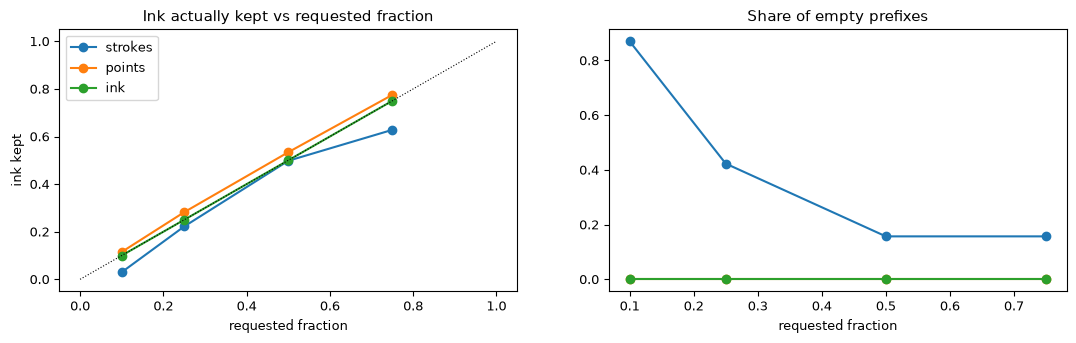

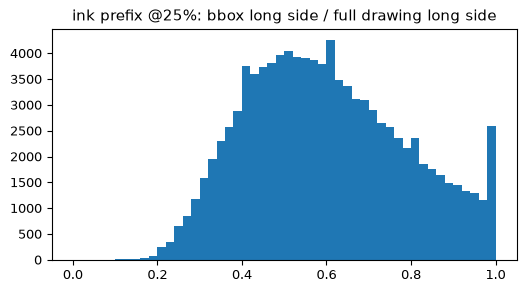

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
for name in PREFIX_FNS:
    s = summary.loc[name]
    axes[0].plot(s.index, s["ink_kept"], "o-", label=name)
    axes[1].plot(s.index, s["empty"], "o-", label=name)
axes[0].plot([0, 1], [0, 1], "k:", lw=.8)
axes[0].set(title="Ink actually kept vs requested fraction", xlabel="requested fraction", ylabel="ink kept")
axes[1].set(title="Share of empty prefixes", xlabel="requested fraction")
axes[0].legend()
savefig("09_prefix_definitions")
plt.show()

s25 = pre[(pre["definition"] == "ink") & (pre["frac"] == 0.25)]["scale_vs_full"]
plt.figure(figsize=(6, 3))
plt.hist(s25, bins=50)
plt.title("ink prefix @25%: bbox long side / full drawing long side")
savefig("09_prefix_scale_leakage")
plt.show()

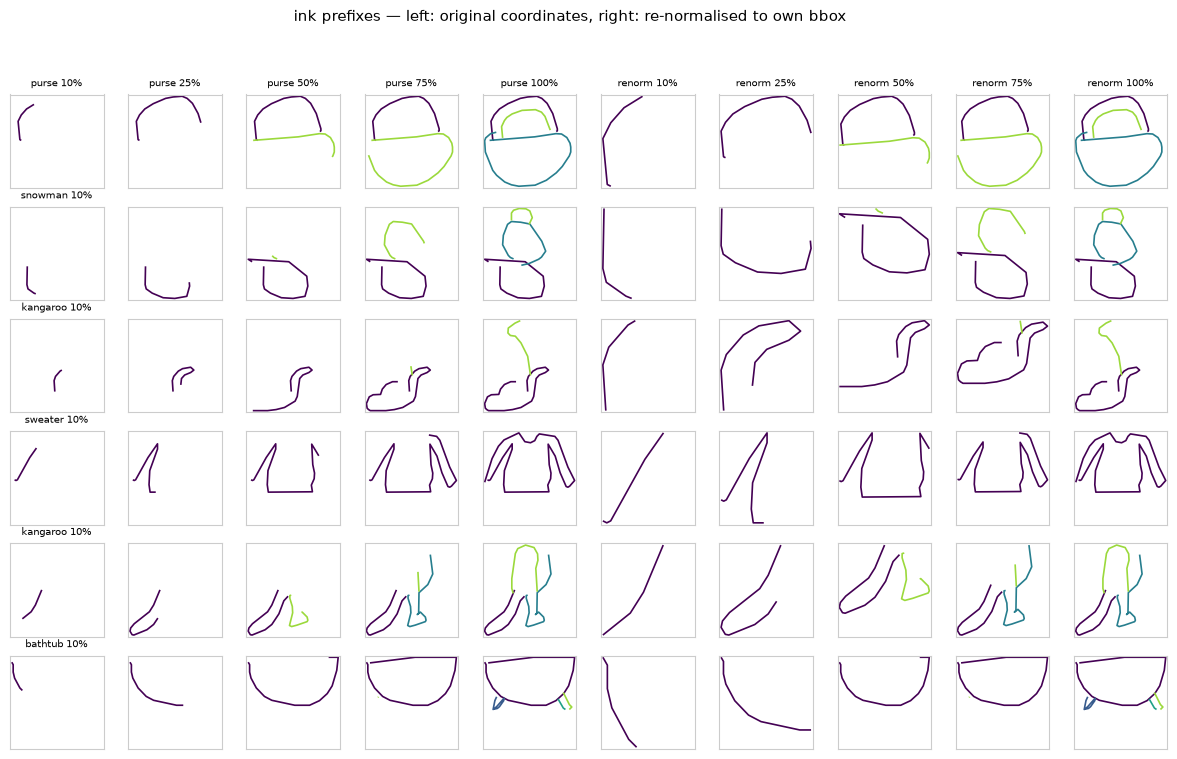

In [24]:
rng = np.random.default_rng(SEED)
pick = rng.choice(len(P), 6, replace=False)
cols = FRACS + [1.0]
fig, axes = plt.subplots(6, 2 * len(cols), figsize=(15, 8.5))
for i, j in enumerate(pick):
    d, word = P[j], prefix_sample["word"].iloc[j]
    for k, f in enumerate(cols):
        p = PREFIX_FNS["ink"](d, f)
        plot_strokes(axes[i, k], p, order_colors=True, title=f"{word} {int(f * 100)}%" if i == 0 or k == 0 else None)
        plot_strokes(axes[i, len(cols) + k], renormalize(p), order_colors=True,
                     title=f"renorm {int(f * 100)}%" if i == 0 else None)
fig.suptitle("ink prefixes — left: original coordinates, right: re-normalised to own bbox")
savefig("09_prefix_examples")
plt.show()

In [25]:
# Prefix rỗng theo số nét tập trung ở đâu? (frac = 0.25, làm tròn xuống)
empty25 = pre[(pre["definition"] == "strokes") & (pre["frac"] == 0.25)]["empty"].values
empty_by_class = pd.Series(empty25, index=prefix_sample["word"].values).groupby(level=0).mean().sort_values()
print("Prefix 25% theo số nét bị rỗng — 5 lớp cao nhất:", empty_by_class.tail(5).round(3).to_dict())
print("5 lớp thấp nhất:", empty_by_class.head(5).round(3).to_dict())

Prefix 25% theo số nét bị rỗng — 5 lớp cao nhất: {'mountain': 0.921, 'square': 0.934, 'star': 0.934, 'boomerang': 0.936, 'triangle': 0.966}
5 lớp thấp nhất: {'ant': 0.008, 'spider': 0.011, 'pig': 0.012, 'owl': 0.022, 'monkey': 0.027}


**Nhận xét.**
* **Theo số nét:** 42% prefix 25% bị rỗng, 87% ở mức 10%. Từ 50% trở đi vẫn còn 15,7%
  prefix rỗng (đúng bằng tỉ lệ hình 1 nét). Lượng mực thực sự giữ lại lệch xa so với mức
  yêu cầu (22% khi yêu cầu 25%, 63% khi yêu cầu 75%), và mức lệch khác nhau giữa các lớp.
* **Theo số điểm:** không bao giờ rỗng và giữ đúng tỉ lệ điểm, nhưng tỉ lệ mực hơi lệch,
  vì điểm đã qua RDP nên phân bố dày ở đoạn cong, thưa ở đoạn thẳng.
* **Theo độ dài mực:** khớp chính xác mức yêu cầu (0,100 / 0,250 / 0,500 / 0,750), không
  bao giờ rỗng, ít phụ thuộc vào cách simplify.
* **Rò rỉ kích thước:** với prefix 25% theo mực, khung bao của prefix chỉ bằng khoảng 58%
  (median) cạnh dài của hình đầy đủ, dao động 37–87% (p10–p90). Nếu đưa prefix vào model
  **ở toạ độ gốc**, độ lớn này cho model biết hình hoàn chỉnh lớn cỡ nào so với phần
  đã vẽ. Khi đang vẽ thật thì không thể có thông tin này.

→ **Quyết định:** định nghĩa prefix **theo độ dài mực**, rồi **chuẩn hoá lại prefix theo
khung bao của chính nó** trước khi tạo raster hay chuỗi.

**Cập nhật:** chuẩn hoá lại chỉ giấu độ lớn của prefix, **không chặn hết rò rỉ**. Lưới toạ độ
số nguyên, mật độ điểm và cạnh gãy vẫn cho biết tỉ lệ prefix so với hình đầy đủ. Số đo và cách
xử lý nằm trong `reports/preprocessing/leak_audit.md`.

### 9b. Định nghĩa prefix đã dùng khi chọn lớp là gì?

`class_selection/shapes.npz` chứa ảnh trung bình 32×32 của phần mở đầu (`early`,
`prefix_frac = 0.25`) và của hình đầy đủ (`full`) cho 340 lớp, nhưng không ghi định
nghĩa prefix. Ta dựng lại ảnh trung bình theo từng định nghĩa ứng viên, vẽ prefix trong
khung của chính nó (`own`) hoặc trong khung của hình đầy đủ (`full`), rồi đo tương quan
Pearson với `early` cho từng lớp.

Hàm vẽ raster ở đây (căn giữa, lề 2 px) được hiệu chỉnh sao cho ảnh trung bình của hình
**đầy đủ** khớp với `shapes.full`. Dòng tham chiếu cuối bảng cho biết mức tương quan
tối đa có thể kỳ vọng (vì khác mẫu và khác chi tiết cách vẽ).

In [26]:
shapes = np.load(SELECTION_DIR / "shapes.npz", allow_pickle=True)
name_idx = {n: i for i, n in enumerate(shapes["names"])}
frac = float(shapes["prefix_frac"])
variants = {
    "strokes floor": lambda d: PREFIX_FNS["strokes"](d, frac),
    "strokes max(1, floor)": lambda d: d[:max(1, math.floor(frac * len(d)))],
    "strokes max(1, round)": lambda d: d[:max(1, round(frac * len(d)))],
    "strokes ceil": lambda d: d[:math.ceil(frac * len(d))],
    "points": lambda d: PREFIX_FNS["points"](d, frac),
    "ink": lambda d: PREFIX_FNS["ink"](d, frac),
}
N_SHAPE = 150
class_idx = {c: np.flatnonzero(prefix_sample["word"].values == c)[:N_SHAPE] for c in classes}
corr = {}
for vname, fn in variants.items():
    for frame in ("own", "full"):
        corr[(vname, frame)] = [
            mean_corr(np.mean([rasterize(fn(P[j]), ref=None if frame == "own" else P[j]) for j in idx], axis=0),
                      shapes["early"][name_idx[c]])
            for c, idx in class_idx.items()]
corr[("reference: full drawing vs shapes.full", "own")] = [
    mean_corr(np.mean([rasterize(P[j]) for j in idx], axis=0), shapes["full"][name_idx[c]])
    for c, idx in class_idx.items()]
corr_df = pd.DataFrame({k: [np.mean(v), np.median(v), np.min(v)] for k, v in corr.items()},
                       index=["mean r", "median r", "min r"]).T.sort_values("mean r", ascending=False)
corr_df.index.names = ["definition", "frame"]
corr_df.round(3).to_csv(TAB / "prefix_definition_vs_selection.csv")
corr_df.round(3)

,,mean r,median r,min r
definition,frame,,,
reference: full drawing vs shapes.full,own,0.929,0.938,0.823
strokes ceil,own,0.878,0.878,0.793
"strokes max(1, round)",own,0.876,0.876,0.787
"strokes max(1, floor)",own,0.865,0.864,0.760
strokes floor,own,0.749,0.802,0.196
strokes ceil,full,0.737,0.797,0.170
"strokes max(1, round)",full,0.734,0.796,0.158
points,own,0.733,0.783,0.124
"strokes max(1, floor)",full,0.731,0.793,0.147


**Nhận xét.** Các định nghĩa **theo số nét, giữ ít nhất 1 nét, vẽ trong khung của
chính prefix** (`ceil` / `max(1, round)` / `max(1, floor)`) cho tương quan gần mức
tham chiếu (≈ 0,87–0,88 so với 0,93). Mọi phương án vẽ trong khung hình đầy đủ, cũng như
các phương án theo điểm hay theo mực, đều thấp hơn rõ. Phép đo này không phân biệt
được `ceil` với `round`. Kết luận rút ra từ số liệu: **lúc chọn lớp, "25% mở đầu" = k nét
đầu (k ≥ 1), chuẩn hoá theo khung riêng.**

**Đối chiếu với mã nguồn:** hàm `prefix` trong `notebooks/1.dataset_collection.ipynb`
dùng đúng `k = max(1, ceil(frac · số nét))`, và hàm `render` scale theo khung của chính
prefix, lề 2 px, căn giữa. Kết quả đo ở trên khớp với mã nguồn.

**Hệ quả cần thống nhất trong nhóm:**
* Với hình 1 nét (15,6% dữ liệu; > 70% ở *star, square, triangle, boomerang*), "25% mở
  đầu" lúc chọn lớp **chính là cả hình**. Khi đó `early_confusability` của các lớp này
  thực chất đo độ giống của hình đầy đủ.
* Nếu thí nghiệm dùng prefix theo mực (đề xuất ở mục 9), thì định nghĩa "mở đầu" lúc
  chọn lớp và lúc đánh giá **khác nhau**. Cần chọn một trong hai: (a) tính lại
  `early_confusability` theo prefix mực cho 100 lớp đã chọn, chỉ để mô tả, không chọn
  lại lớp; hoặc (b) ghi rõ sự khác biệt này trong báo cáo như một giới hạn.
* Việc chuẩn hoá theo khung riêng lúc chọn lớp **nhất quán** với quyết định chống rò
  rỉ ở mục 9.

## 10. Liên hệ với vai trò lớp khi chọn lớp (confusable / control / included)

In [27]:
per_class = pd.DataFrame({
    "n_strokes_median": df.groupby("word")["n_strokes"].median(),
    "n_points_median": by_class.median(),
    "n_points_p99": by_class.quantile(.99),
    "single_stroke_share": single,
    "recognized_rate": rec_by_class,
    "nonconform_share": rate,
    "tiny_le3_share": (df["n_points"] <= 3).groupby(df["word"]).mean(),
    "top_country_share": per_class_top,
})
per_class = per_class.join(frozen.set_index("class")[["role", "tier", "cluster", "early_confusability", "early_late_gap"]])
per_class.round(4).to_csv(TAB / "class_summary.csv")
by_role = per_class.groupby("role").agg(
    n_classes=("recognized_rate", "size"),
    **{c: (c, "mean") for c in ["n_strokes_median", "n_points_median", "single_stroke_share",
                                "recognized_rate", "nonconform_share", "early_confusability"]})
by_role.round(3)

,n_classes,n_strokes_median,n_points_median,single_stroke_share,recognized_rate,nonconform_share,early_confusability
role,,,,,,,
confusable,76,4.217,41.697,0.177,0.919,0.282,0.813
control,21,5.048,45.810,0.099,0.914,0.281,0.584
included,3,6.667,61.667,0.033,0.906,0.296,0.811


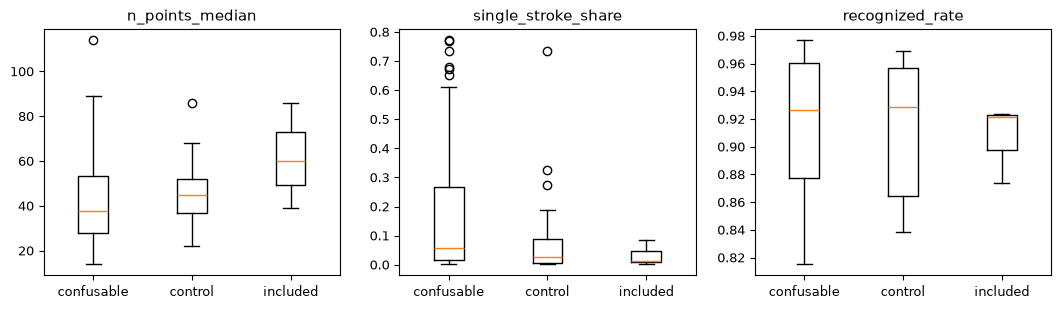

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
roles = ["confusable", "control", "included"]
for ax, col in zip(axes, ["n_points_median", "single_stroke_share", "recognized_rate"]):
    ax.boxplot([per_class.loc[per_class["role"] == r, col] for r in roles], tick_labels=roles)
    ax.set_title(col)
savefig("10_by_role")
plt.show()

**Nhận xét.** Hai nhóm *confusable* (76 lớp) và *control* (21 lớp) có số nét, số điểm,
tỉ lệ recognized và tỉ lệ lệch chuẩn hoá tương đương nhau. Như vậy khác biệt về
độ khó ở phần mở đầu (`early_confusability` 0,81 so với 0,58) **không đi kèm** khác biệt
lớn về chất lượng nhãn hay độ dài chuỗi, nên việc so sánh hai nhóm khá công bằng. Ngoại lệ:
nhóm confusable có nhiều hình 1 nét hơn (17,7% so với 9,9%). Đây lại chính là các hình
mà định nghĩa prefix theo số nét xử lý kém (mục 9 và 9b).

## 11. Ví dụ hình vẽ của cả 100 lớp

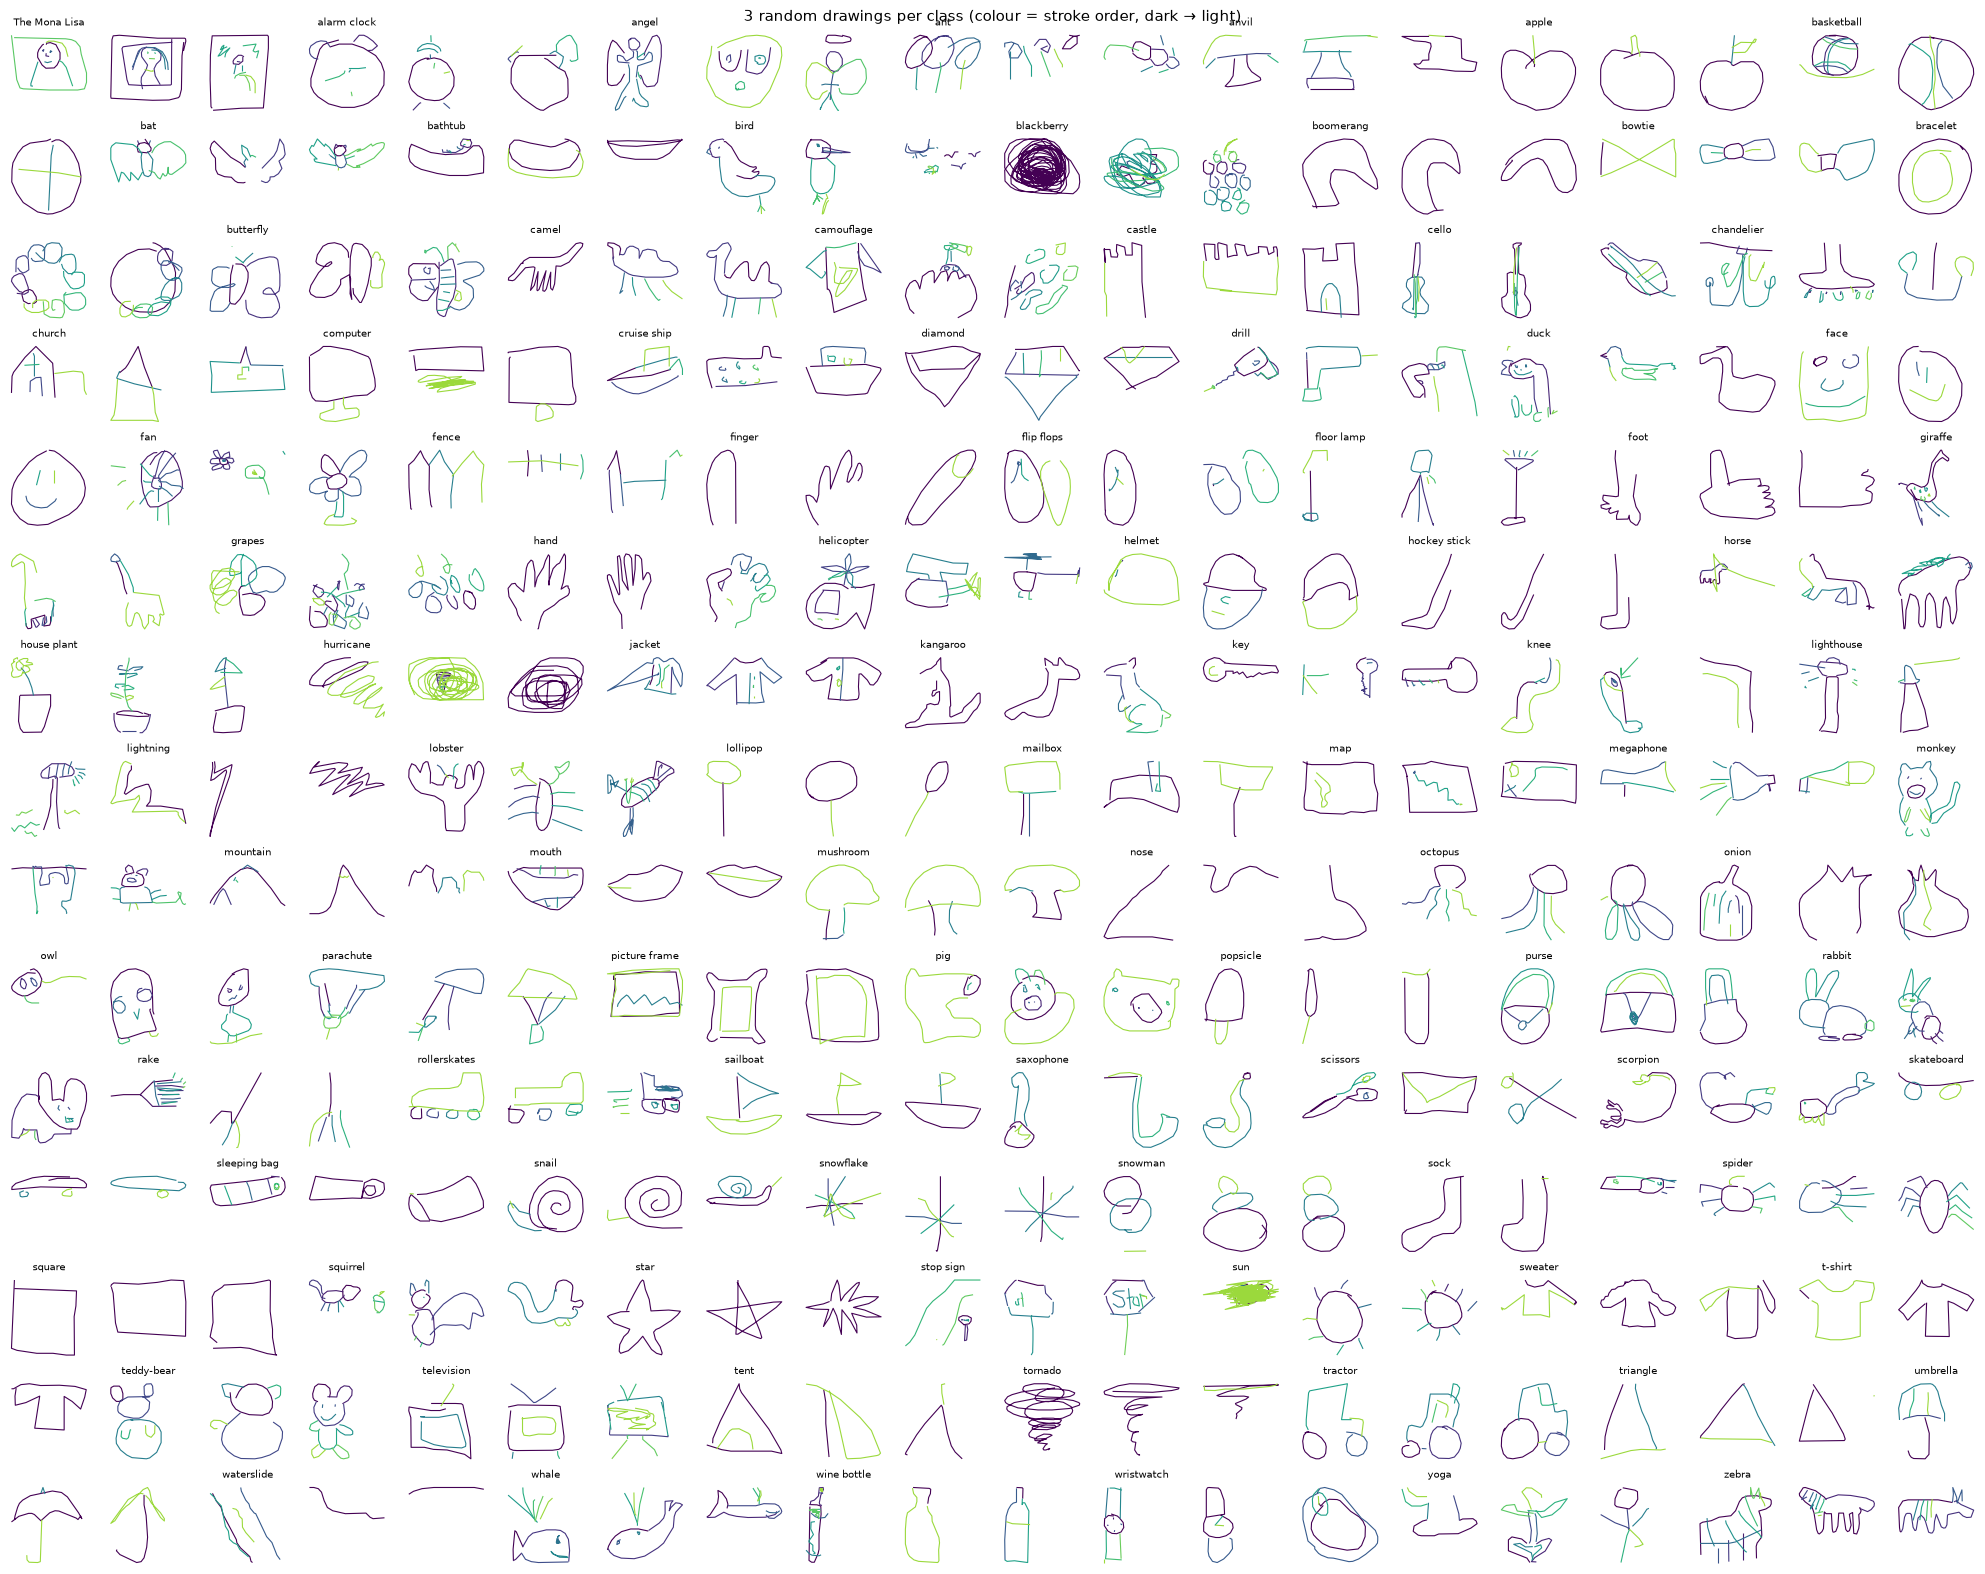

In [29]:
gallery = df.groupby("word", group_keys=False).sample(3, random_state=SEED).sort_values(["word", "row"])
G = load_drawings(gallery["row"])
fig, axes = plt.subplots(15, 20, figsize=(20, 16))
for i, ax in enumerate(axes.flat):
    if i < len(G):
        plot_strokes(ax, G[i], order_colors=True, lw=.8,
                     title=gallery["word"].iloc[i] if i % 3 == 0 else None, frame=False)
    else:
        ax.axis("off")
fig.suptitle("3 random drawings per class (colour = stroke order, dark → light)")
plt.tight_layout()
savefig("11_gallery")
plt.show()

## 12. Tổng hợp số liệu

In [30]:
findings = pd.DataFrame(FINDINGS, columns=["mục", "chỉ số", "giá trị"])
findings.to_csv(TAB / "findings.csv", index=False)
findings

,mục,chỉ số,giá trị
0,1,số mẫu,"3,000,000"
1,1,số lớp,100
2,1,mẫu/lớp (min–max),"30,000–30,000"
3,1,key_id trùng,0
4,2,nhóm hình trùng,39
5,2,hàng thừa (tổng - số nhóm),60
6,2,nhóm trùng cùng lớp,0
7,2,nhóm trùng khác lớp (mâu thuẫn nhãn),39
8,2,số hàng thuộc nhóm khác lớp,99
9,3,hình có ≤ 1 điểm,0


## 13. Các quyết định tiền xử lý rút ra

| # | Phát hiện | Quyết định cho phần B (tiền xử lý) |
|---|---|---|
| 1 | 3.000.000 mẫu, đúng 30.000/lớp; `key_id` không trùng; danh sách lớp khớp bản đã đóng băng (sha256) | Không cần cân bằng lại lớp. Dùng `key_id` làm khoá cho file chia tập |
| 2 | 39 nhóm hình trùng (99 hàng), **tất cả khác lớp** và đều là đoạn thẳng 2 điểm | Loại 99 hàng này |
| 3 | 851 hình ≤ 3 điểm (71,7% vẫn recognized); 51 hình chỉ gồm chấm | Gắn cờ, không loại. Hàm raster phải vẽ được chấm |
| 4 | 28,2% hình lệch quy ước min=0/max=255, nhưng 99,15% chỉ lệch ≤ 2 px | Tự chuẩn hoá lại mọi hình (dời về 0, cạnh dài = 255, giữ tỉ lệ) |
| 5 | 15,6% hình chỉ có 1 nét (> 70% ở một số lớp) | Không định nghĩa prefix theo số nét |
| 6 | Số điểm p99 = 151, nhưng lớp *blackberry* chỉ 78% hình ≤ 160 điểm | Cap chuỗi 256 điểm (≥ 96% hình mọi lớp còn nguyên). Phần dư thì giảm mẫu, không cắt cụt |
| 7 | 8,24% `recognized=False`, nhiều nét hơn gần gấp đôi; khác nhau theo lớp và nước | Giữ, kèm cột cờ. Val/test giữ đủ để báo cáo riêng. Mốc 100% là lúc lượt vẽ dừng, không phải vẽ xong |
| 8 | US 44,3%; recognized 0,80–0,95 giữa các nước; 30 nước có ≥ 100 mẫu/lớp | Chia phân tầng theo lớp. Tập test theo quốc gia là tuỳ chọn, chốt trước khi train |
| 9 | Prefix theo mực khớp đúng tỉ lệ, không rỗng; prefix ở toạ độ gốc lộ kích thước hình đầy đủ (median 58% ở mức 25%) | Prefix theo độ dài mực, chuẩn hoá lại theo khung riêng. Bước này chưa chặn hết rò rỉ, xem `reports/preprocessing/leak_audit.md` |
| 9b | Lúc chọn lớp, "mở đầu" = `max(1, ceil(0,25·số nét))` nét đầu, khung riêng (đã đối chiếu mã nguồn) | Thống nhất định nghĩa trong nhóm, hoặc ghi rõ khác biệt |
| 10 | Confusable và control tương đương về độ dài, nhiễu nhãn; confusable nhiều hình 1 nét hơn | So sánh hai nhóm là công bằng. Báo cáo kết quả theo nhóm |